In [1]:
# ==============================================================================
# 1: Импорты
# ==============================================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os

from Magnetic_Field import (
    make_A_phi, A_phi_gaussian, A_phi_uniform, A_phi_power, A_phi_screen,
    compute_B_from_A_phi, extract_axial_profiles,
    save_field_to_csv, load_field_from_csv,
    compute_field_from_B
)
from methods import (
    build_operators, forward_rm, regularizer, RegularizedInversion,
    choose_alpha_lcurve, electron_density, rel_error, relative_error,
    add_noise, plot_recovery, plot_sweep, plot_A_and_B,
    plot_A_phi_profiles, plot_B_profiles, 
    append_run_to_csv, load_runs,
    plot_all_true_fields, plot_all_recovered_fields,
    plot_all_rm, plot_all_rm_noisy,
)

try:
    plt.style.use('seaborn-v0_8-whitegrid')
except OSError:
    plt.style.use('default')

print("✅ Модули загружены.")


✅ Модули загружены.


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from methods import load_runs, plot_all_errors_bar, plot_error_vs_noise

### ============================
### Для всех регуляризаторов
### ============================

In [3]:
REG_TAG = {
    "None": "none",
    "Zero":  "zero_order",
    "First": "first_order",
    "Second": "second_order",
}

In [4]:
def _fname(Result_dir, delta, reg_kind="second_order", type_B = "Bz", tmp_str = '_(var_B)'): 
        '''
        Args:
            type_B = "Bz" / "Bphi"
        '''
    
        return os.path.join(
            Result_dir,
            f"{type_B}{tmp_str}_noise_{delta}_reg_{reg_kind}.csv"
        )
    

In [5]:
def plot_error_vs_noise(csv_paths, deltas,
                        err_key='err_Bz',
                        title=None, ax=None,
                        loglog=True, annotate_runs=True):
    if ax is None:
        fig, ax = plt.subplots(figsize=(9, 6))

    # --- собираем ошибки ---
    err_by_run = {}
    for d in deltas:
        fname = csv_paths[d]
        if not os.path.exists(fname):
            print(f"⚠️ Файл не найден: {fname}")
            continue
        _, runs = load_runs(fname)
        for name, data in runs.items():
            if err_key not in data:
                continue
            arr = np.atleast_1d(np.asarray(data[err_key], float))
            err_by_run.setdefault(name, {})[d] = float(np.mean(arr))

    if not err_by_run:
        print("Нет данных для построения графика.")
        return ax

    cmap = plt.get_cmap('viridis')
    names = sorted(err_by_run.keys())
    n = len(names)

    # -----------------------------------------------------------------
    # вспомогательная функция: нарисовать линию ε = δ в нужном масштабе
    # -----------------------------------------------------------------
    def _draw_eps_eq_delta(color='k', ls='--', lw=1, alpha=0.6, label=r'$\varepsilon = \delta$'):
        pos_deltas = [d for d in deltas if d > 0] or [d for d in deltas]
        if not pos_deltas:
            return
        xmin, xmax = min(pos_deltas), max(pos_deltas)
        if xmin == xmax:
            xmin, xmax = xmin * 0.5, xmax * 2 or 1.0
        xx = np.linspace(xmin, xmax, 50) if not loglog \
             else np.logspace(np.log10(xmin), np.log10(xmax), 50)
        ax.plot(xx, xx, color=color, ls=ls, lw=lw, alpha=alpha, label=label)

    # -----------------------------------------------------------------
    # ветка: по одной кривой на каждый run_name
    # -----------------------------------------------------------------
    if annotate_runs:
        for i, name in enumerate(names):
            ds = sorted(err_by_run[name].keys())
            es = [err_by_run[name][d] for d in ds]
            color = cmap(i / max(n - 1, 1))

            if loglog:
                ds_plot = [max(x, 1e-6) for x in ds]
                es_plot = [max(x, 1e-6) for x in es]
                ax.loglog(ds_plot, es_plot, 'o-', color=color, lw=1.8,
                          ms=6, label=name)
            else:
                ax.plot(ds, es, 'o-', color=color, lw=1.8, ms=6, label=name)

        _draw_eps_eq_delta()

    # -----------------------------------------------------------------
    # ветка: усреднение по всем запускам
    # -----------------------------------------------------------------
    else:
        ds, es_mean, es_std = [], [], []
        for d in sorted(deltas):
            vals = [err_by_run[name][d]
                    for name in err_by_run if d in err_by_run[name]]
            if not vals:
                continue
            ds.append(d)
            es_mean.append(float(np.mean(vals)))
            es_std.append(float(np.std(vals)))

        if loglog:
            ds_plot = [max(x, 1e-6) for x in ds]
            es_plot = [max(x, 1e-6) for x in es_mean]
            ax.errorbar(ds_plot, es_plot, yerr=es_std, fmt='o-',
                        color='tab:blue', lw=2, ms=7, capsize=4,
                        label='Среднее ± σ')
        else:
            ax.errorbar(ds, es_mean, yerr=es_std, fmt='o-',
                        color='tab:blue', lw=2, ms=7, capsize=4,
                        label='Среднее ± σ')

        _draw_eps_eq_delta()

    ax.set_xlabel(r'Уровень шума $\delta$')
    ax.set_ylabel(r'Относительная ошибка $\varepsilon_{B_z}$')
    ax.set_title(title or r"Зависимость ошибки восстановления от уровня шума")
    ax.grid(True, which='both' if loglog else 'major', ls=':', alpha=0.5)
    ax.legend(fontsize=8)
    return ax

None
results_2110/None\Bphi_(rho)_(var_B)_noise_0.0_reg_none.csv
Zero
results_2110/Zero\Bphi_(rho)_(var_B)_noise_0.0_reg_zero_order.csv
First
results_2110/First\Bphi_(rho)_(var_B)_noise_0.0_reg_first_order.csv
Second
results_2110/Second\Bphi_(rho)_(var_B)_noise_0.0_reg_second_order.csv


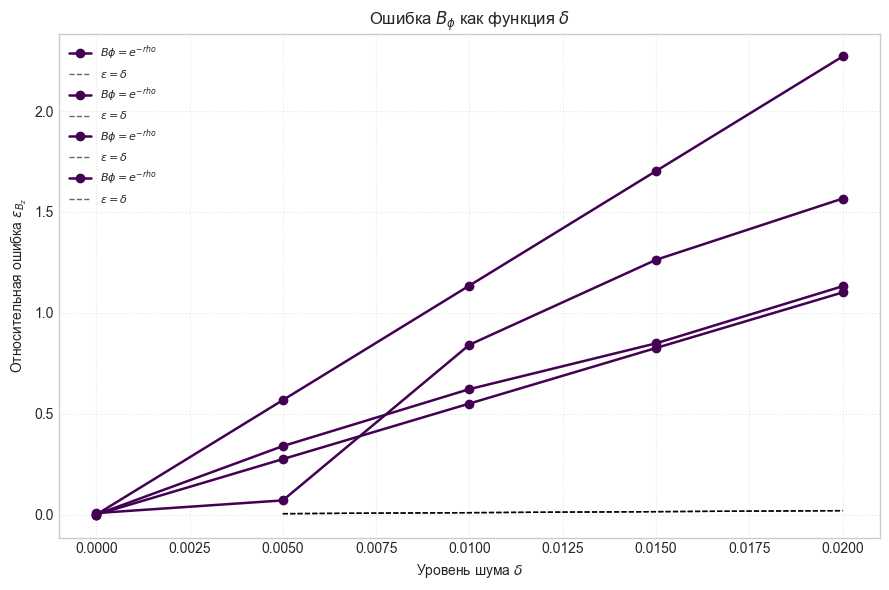

In [6]:
fig, ax = plt.subplots(figsize=(9, 6))

for name_type in REG_TAG:
    print(name_type)
    REG_KIND = REG_TAG[name_type]
    RESULTS_DIR = f"results_2110/{name_type}"
    deltas_plot = [0.0, 0.005, 0.01, 0.015, 0.02]

    csv_paths_bphi = {d: _fname(RESULTS_DIR, d, REG_KIND, 'Bphi', '_(rho)_(var_B)') for d in deltas_plot}
    
    print(_fname(RESULTS_DIR, deltas_plot[0], REG_KIND, 'Bphi', '_(rho)_(var_B)') )
    
    fl_LOGLOG = False
    
    # Проверяем, есть ли хотя бы один файл для B_phi
    if any(os.path.exists(f) for f in csv_paths_bphi.values()):
        # --- 2) Ошибка vs δ: по кривой на каждый run ---
        
        plot_error_vs_noise(csv_paths_bphi, deltas_plot, err_key='err_Bphi',
                            title=r"Ошибка $B_\phi$ как функция $\delta$",
                            ax=ax, loglog=fl_LOGLOG, annotate_runs=True)

    else:
        print("⚠️ Файлы для B_phi не найдены. Пропускаем графики.")
        
plt.tight_layout(); plt.show()
        

In [7]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

REG_TAG = {
    "None":   "none",
    "Zero":   "zero_order",
    "First":  "first_order",
    "Second": "second_order",
}


def _fname(result_dir, delta, reg_kind, type_B, tmp_str):
    return os.path.join(
        result_dir,
        f"{type_B}{tmp_str}_noise_{delta}_reg_{reg_kind}.csv"
    )


def _read_error_from_csv(csv_path, view, err_key):
    """
    Читает CSV и возвращает среднее по столбцу `<view>__<err_key>`.
    Если столбца нет — возвращает None.
    """
    df = pd.read_csv(csv_path)
    col = f"{view}__{err_key}"
    if col not in df.columns:
        return None
    return float(df[col].mean())


def plot_regs_for_view(
        type_B,                 # "Bz" | "Bphi"
        view,                   # вид функции, префикс столбца: "Bz_constant", "Bz = $e^{-\\rho^2}$", ...
        deltas,                 # [0.0, 0.005, ...]
        err_key=None,           # по умолчанию f"err_{type_B}"
        reg_tag=REG_TAG,
        base_dir="results_2110",
        tmp_str="_(rho)_(var_B)",
        ax=None,
        loglog=False,
        title=None,
        ylabel=None,
        xlabel=r'Уровень шума $\delta$',
        draw_ref=True,
        ref_label=r'$\varepsilon = \delta$',
        figsize=(10, 6),
        cmap='tab10',
        markers=None,
        linestyles=None,
):
    """
    Строит «ошибка vs δ» для одного вида функции и одного типа B:
        - по одной кривой на каждый регуляризатор (None/Zero/First/Second).
    """
    if err_key is None:
        err_key = f"err_{type_B}"

    if ax is None:
        fig, ax = plt.subplots(figsize=figsize)

    # ---------- 1. Собираем данные ----------
    reg_labels = list(reg_tag.keys())
    palette = plt.get_cmap(cmap)
    colors = {r: palette(i / max(len(reg_labels) - 1, 1))
              for i, r in enumerate(reg_labels)}

    default_ls = ['-', '--', '-.', ':', (0, (3, 1, 1, 1))]
    default_mk = ['o', 's', '^', 'D', 'v', 'P', 'X', '*']
    ls_map = linestyles or {r: default_ls[i % len(default_ls)]
                            for i, r in enumerate(reg_labels)}
    mk_map = markers or {r: default_mk[i % len(default_mk)]
                         for i, r in enumerate(reg_labels)}

    curves = {}   # reg_label -> (ds, es)
    for reg_label, reg_kind in reg_tag.items():
        ds, es = [], []
        for d in sorted(deltas):
            results_dir = os.path.join(base_dir, reg_label)
            fname = _fname(results_dir, d, reg_kind, type_B, tmp_str)
            if not os.path.exists(fname):
                print(f"⚠️ [{reg_label}] нет файла: {fname}")
                continue
            val = _read_error_from_csv(fname, view, err_key)
            if val is None:
                print(f"⚠️ [{reg_label}] в {fname} нет столбца "
                      f"'{view}__{err_key}'")
                continue
            ds.append(d)
            es.append(val)
        if ds:
            curves[reg_label] = (ds, es)

    if not curves:
        print(f"Нет данных для {type_B}, вид '{view}'.")
        return ax

    # ---------- 2. Рисуем ----------
    eps_floor = 1e-6
    for reg_label, (ds, es) in curves.items():
        if loglog:
            ds_p = [max(x, eps_floor) for x in ds]
            es_p = [max(x, eps_floor) for x in es]
            ax.loglog(ds_p, es_p,
                      ls=ls_map[reg_label], marker=mk_map[reg_label],
                      color=colors[reg_label], lw=2, ms=6,
                      label=reg_label)
        else:
            ax.plot(ds, es,
                    ls=ls_map[reg_label], marker=mk_map[reg_label],
                    color=colors[reg_label], lw=2, ms=6,
                    label=reg_label)

    # ---------- 3. Опорная линия ε = δ ----------
    if draw_ref:
        pos = [d for d in deltas if d > 0]
        if pos:
            xmin, xmax = min(pos), max(pos)
            if xmin == xmax:
                xmin, xmax = xmin * 0.5, xmax * 2.0
            xx = (np.logspace(np.log10(xmin), np.log10(xmax), 100)
                  if loglog else np.linspace(xmin, xmax, 100))
            ax.plot(xx, xx, 'k--', lw=1, alpha=0.6, label=ref_label)

    # ---------- 4. Оформление ----------
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel or rf'$\varepsilon_{{{type_B}}}$')
    ax.set_title(title or f"{type_B}: {view}")
    ax.grid(True, which='both' if loglog else 'major', ls=':', alpha=0.5)
    ax.legend(fontsize=9)

    return ax

In [8]:
def B_z_constant(rho, B0=1.0):
    return B0 * rho**0

def B_z_gauss(rho, B0=1.0, rho_scale=1.0):
    return B0 * np.exp(-(rho / rho_scale)**2)

def B_z_power2(rho, B0=0.0025):
    return B0 * rho**2

def B_z_gauss_power2(rho, B0=1.0, rho_scale=1.0):
    return B0 * rho**2 * np.exp(-(rho / rho_scale)**2)


variants_Bz = {
    "Bz_constant":  B_z_constant,
    r"Bz = $(B0=0.1)$ \rho^2":  B_z_power2,
    r"Bz = $e^{-\rho^2}$": B_z_gauss,
    r"Bz = $\rho^2 e^{-\rho^2}$": B_z_gauss_power2,
}

def B_phi_exp_rho(rho, z, B0=1.0, z_scale=1.0, rho_scale=1.0):
    return B0 * np.exp(-rho / rho_scale)

variants_B_phi = {
#    r"$B\phi = e^{-z}$" : B_phi_exp_rho,
    r"$B\phi = e^{-rho}$" : B_phi_exp_rho
}



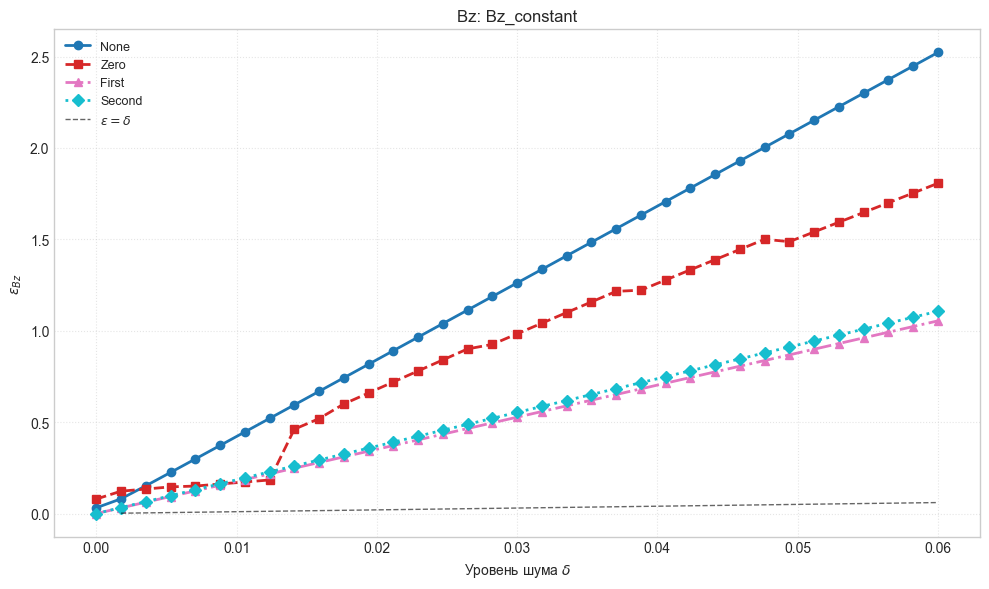

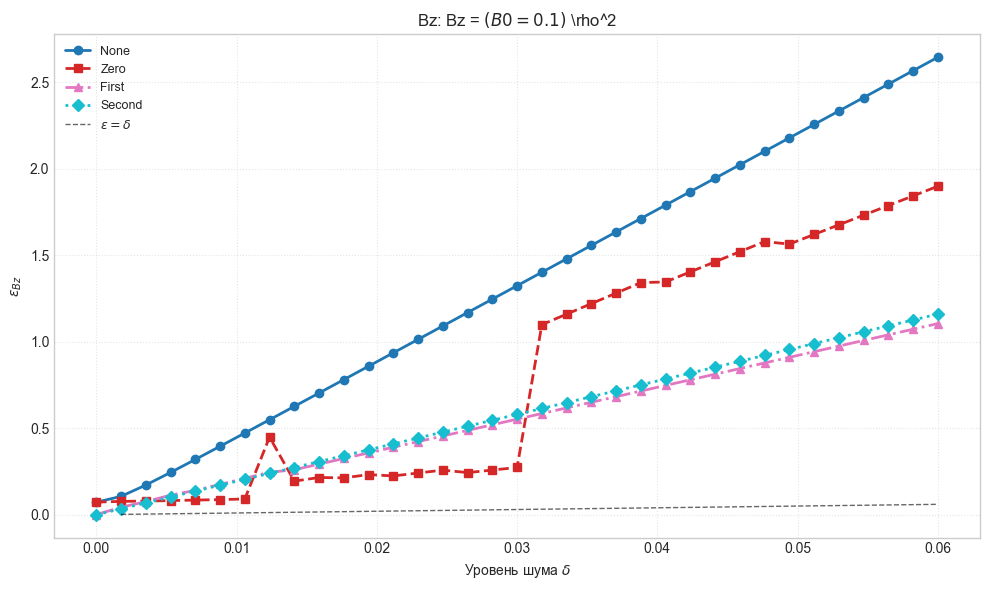

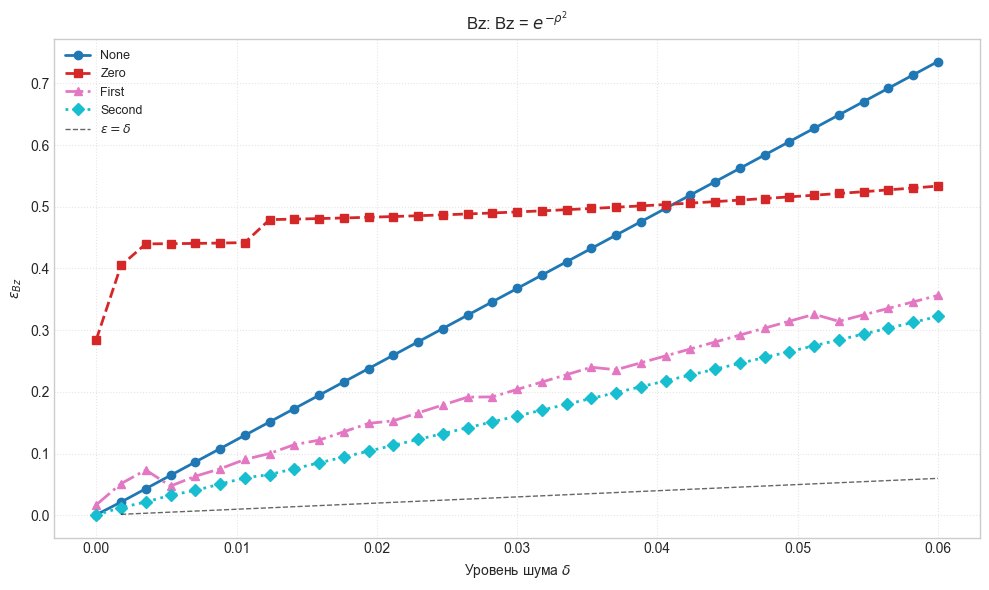

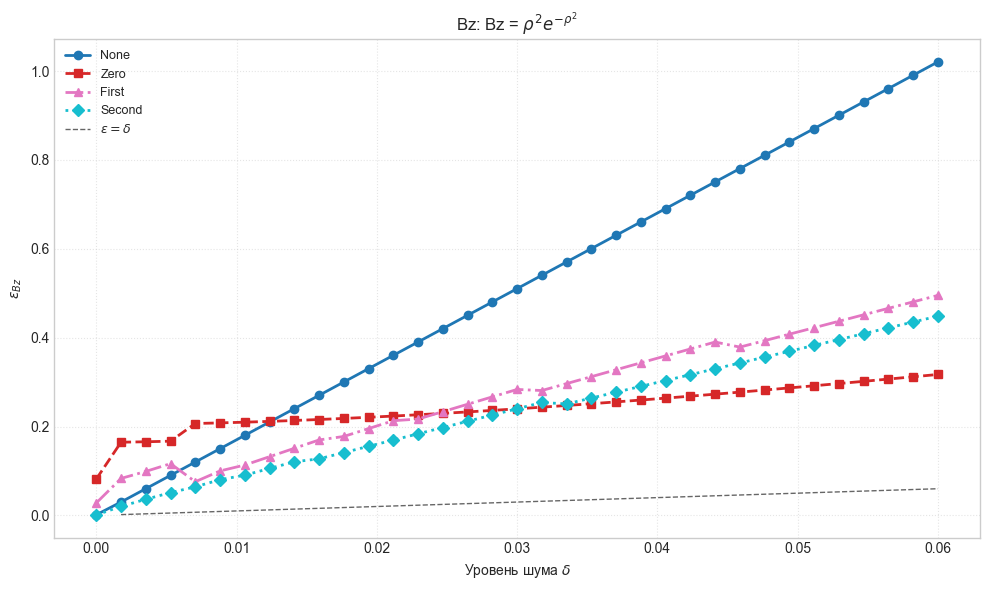

In [9]:

deltas = np.linspace(0.0, 0.06, 35)
deltas_plot = deltas # [0.0, 0.005, 0.01, 0.015, 0.02, 0.03, 0.04, 0.05, 0.06]
VIEW = "Bz_constant"        # вид функции, как в заголовке CSV
# VIEW = r"$B\phi = e^{-rho}$"
for name_Bz in variants_Bz:
    VIEW = name_Bz
    fig, ax = plt.subplots(figsize=(10, 6))
    plot_regs_for_view(
        type_B="Bz",
        view=VIEW,
        deltas=deltas_plot,
        tmp_str="_(rho)_(var_B)",
        base_dir="results_2110",
        loglog=False,
        ax=ax,
    )
    plt.tight_layout(); plt.show()

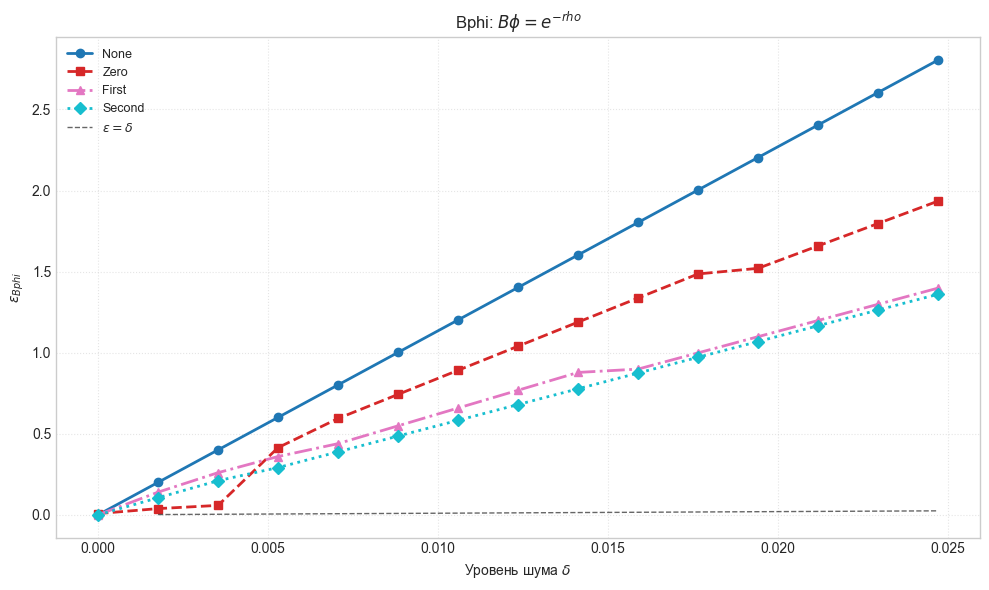

In [10]:
type_B = "Bphi"
deltas_plot = deltas[deltas < 0.025] # [0.0, 0.005, 0.01, 0.015, 0.02]
for name_Bphi in variants_B_phi:
    VIEW = name_Bphi
    
    fig, ax = plt.subplots(figsize=(10, 6))
    
    plot_regs_for_view(
        type_B= type_B,
        view=VIEW,
        deltas=deltas_plot,
        tmp_str="_(rho)_(var_B)",
        base_dir="results_2110",
        loglog=False,
        ax=ax,
    )
    plt.tight_layout(); plt.show()